# Homework 4

Importing the data from the public repo

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# turn data into date frame

# describing the data so you don't have to switch back and forth from editor to repo website
print(heart_disease.metadata)
print(heart_disease.variables)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

## Data:
Checking the info on the features and getting count of null values

In [3]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


In [4]:
y.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   num     303 non-null    int64
dtypes: int64(1)
memory usage: 2.5 KB


I am going to want to change the variable values of heart disease detection because otherwise the model will be doing 5 degrees of classification

In [5]:
y.describe()

,num
count,303.000000
mean,0.937294
std,1.228536
min,0.000000
25%,0.000000
50%,0.000000
75%,2.000000
max,4.000000


changing the values 1-4 inside the target frame into just 1 so that the model trains on whether there is heart disease or not and not how bad the heart disease may be

In [6]:
y = y['num']
y = (y > 0).astype(int)
# svc pipeline later on will need a 1d array, and it was a data frame
y.info()

<class 'pandas.core.series.Series'>
RangeIndex: 303 entries, 0 to 302
Series name: num
Non-Null Count  Dtype
--------------  -----
303 non-null    int64
dtypes: int64(1)
memory usage: 2.5 KB


In [7]:
X.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


Checking the Null sum

In [8]:
X.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


^^ They don't make enough of a difference to matter but the columns themselves could prove useful so I will just impute on the data instead of removing the columns
Also, the cleveland version of the database is completely clean of false values. So I only need to deal with the little amount of null values present

## Setting up the plot for later visualization
just setting the size of the parts

In [9]:
import matplotlib.pyplot as plt
import numpy as np

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=10)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

## Pipeline Definition
basic pipeline definition

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

numCols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
catCols = ['thal', 'slope', 'sex', 'cp', 'fbs', 'restecg', 'exang']

numPipeline1 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
numPipeline2 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

catPipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('cat_encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessPipe1 = ColumnTransformer([
    ('num', numPipeline1, numCols),
    ('cat', catPipeline, catCols)
])

preprocessPipe2 = ColumnTransformer([
    ('num', numPipeline2, numCols),
    ('cat', catPipeline, catCols)
])

## Fitting and transforming it in the pipeline

cloned the pipeline so I can use it again and then fitting and transforming the data so I can visualize it

In [11]:
from sklearn.base import clone
pipe1 = clone(preprocessPipe1)
pipe2 = clone(preprocessPipe2)
transformed1 = pipe1.fit_transform(X)
transformed2 = pipe2.fit_transform(X)

## Plotting the scaled data
After processing data through the pipe, we get a numpy array so I have to extract the column names.
Then, I define the plot parameters and plot the data itself. I used a boxplot to check the variance of the data and see what kind of skewedness I am dealing with.

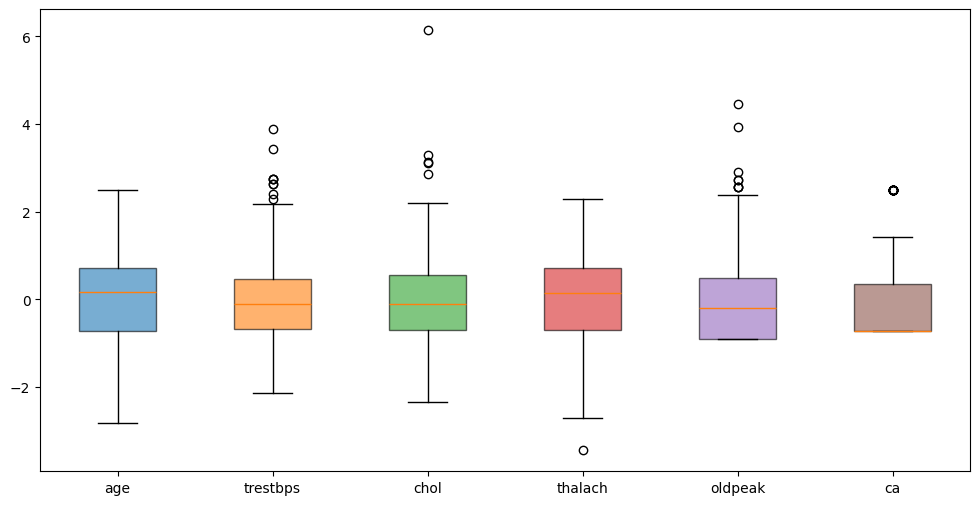

In [12]:
names = pipe1.get_feature_names_out()
df_scaled = pd.DataFrame(transformed1, columns=names)

fig, ax = plt.subplots(figsize=(12, 6))

# remove the encoded features because they have no use in a box plot
num_scaled = df_scaled[[c for c in names if c.startswith('num__')]]
labels = [c.removeprefix('num__') for c in num_scaled.columns]

bp = ax.boxplot(num_scaled.values, tick_labels=labels, patch_artist=True)

# one color per feature
for box, color in zip(bp['boxes'], plt.cm.tab10.colors):
    box.set_facecolor(color)
    box.set_alpha(0.6)

plt.show()

The plot above shows useful information. Age and thalach are basically symmetrical. trestbps, chol, and oldpeak seem to have some right skewedness. ca cuts off at 0 but that's just because it's values are limited to just 0-3 and most values are 0 so 3 looks to be an outlier here. Nothing wrong with that. Thalach seems to be a bit out of the ordinary as it is the only one with an outlier below the box shown.

Doing the same but for MinMaxScaler to see what the differences are. Maybe it will deal with the data in a better way? I highly doubt it but good to check.

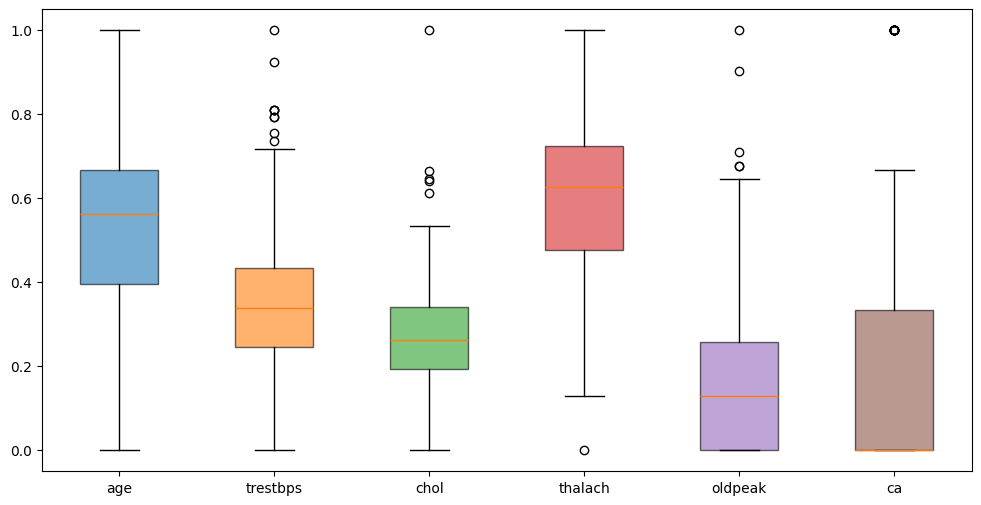

In [13]:
names = pipe2.get_feature_names_out()
df_scaled = pd.DataFrame(transformed2, columns=names)

fig, ax = plt.subplots(figsize=(12, 6))

# remove the encoded features because they have no use in a box plot
num_scaled = df_scaled[[c for c in names if c.startswith('num__')]]
labels = [c.removeprefix('num__') for c in num_scaled.columns]

bp = ax.boxplot(num_scaled.values, tick_labels=labels, patch_artist=True)

# one color per feature
for box, color in zip(bp['boxes'], plt.cm.tab10.colors):
    box.set_facecolor(color)
    box.set_alpha(0.6)

plt.show()

MinMaxScaler is controlled by the extremes. You can see that the values only range from 0-1, as expected, and this caused a lot of the data to get crunched in a way that doesn't really represent the data well.
For this reason, I think I am going to use StandardScaler

## Defining SVC Pipeline

Here, I am making the SVC and decision tree pipelines for later use
I will also split the data 80-20 and define a dictionary for both that will be used to iterate through later for qol

In [14]:
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

Xtrain, Xtest, yTrain, yTest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


svcPipe = Pipeline([
    ('preprocess', clone(preprocessPipe1)),
    ('svc', SVC(kernel='rbf', probability=True, random_state=42))
])

treePipe = Pipeline([
    ('preprocess', clone(preprocessPipe1)),
    ('tree', DecisionTreeClassifier(max_depth=5, random_state=42))
])

# fit the models
svcPipe.fit(Xtrain, yTrain)
treePipe.fit(Xtrain, yTrain)

# define a dictionary for the two models so I can just iterate through them later for evaluation
models = {"SVM": svcPipe, "Tree": treePipe}

## Evaluation of the model

For all of the following code cells, I use a basic iterator to go through both models to get a back to back comparison. This just allows me to not have to make a definition for each graph I am using as that would be very annoying and time consuming

Displaying the confusion matrix as a visual graph to digest is easier than a raw array
The confusion matrices show that SVM is slightly better than the decision tree.
The decision tree had more false positives and negatives.
Though there is a common trend for both which is both have more false positives than false negatives

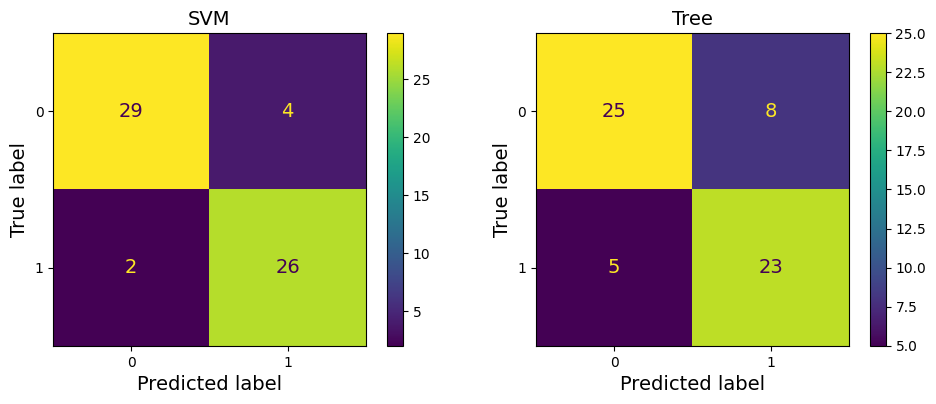

In [15]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    yPred = model.predict(Xtest)
    ConfusionMatrixDisplay.from_predictions(yTest, yPred, ax=ax)
    ax.set_title(name)

plt.tight_layout()
plt.show()

For the ROC AUC curve, the result is similar to above. The svm is better but the decision tree is still decent
It just grows slower than the svm. Both are still much better than guessing randomly however. So it is still a good result.
If the models were perfect, they would be in the top left corner, but they are not perfect. They are good enough

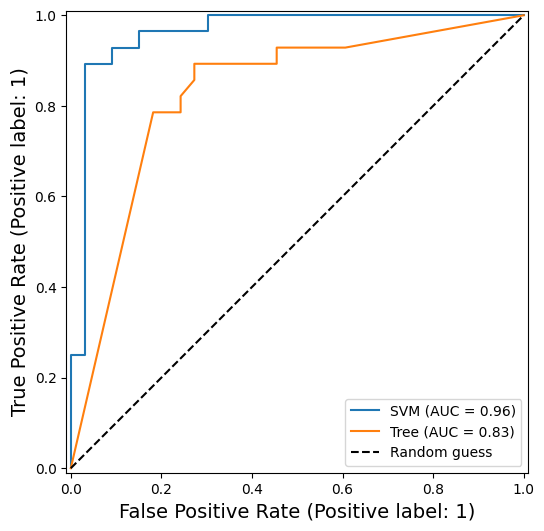

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, model in  models.items():
    yProb = model.predict_proba(Xtest)[:, 1]
    RocCurveDisplay.from_predictions(yTest, yProb, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')
ax.legend()
plt.show()

Again, svm is stronger here. Common result.
Both are decent though. SVM has a high precision and recall as well as f1. The decision tree has a lower for all categories but it still has a strength on it's own.
If I didn't limit it's depth, these numbers would be way lower than they are now. That is how I settled on a max depth of 5. When it was infinite in depth, it was overtuned and the f1 score as well as the precision was drastically lower than it is here

In [17]:
reports = {}
for name, model in models.items():
    yPred = model.predict(Xtest)
    reports[name] = pd.DataFrame(classification_report(yTest, yPred, output_dict=True)).T

pd.concat(reports, axis=1).round(2)

SVM                              Tree                  \
             precision recall f1-score support precision recall f1-score   
0                 0.94   0.88     0.91    33.0      0.83   0.76     0.79   
1                 0.87   0.93     0.90    28.0      0.74   0.82     0.78   
accuracy          0.90   0.90     0.90     0.9      0.79   0.79     0.79   
macro avg         0.90   0.90     0.90    61.0      0.79   0.79     0.79   
weighted avg      0.90   0.90     0.90    61.0      0.79   0.79     0.79   

                      
             support  
0              33.00  
1              28.00  
accuracy        0.79  
macro avg      61.00  
weighted avg   61.00

## Cross Validation

Using stratifiedKFold to make sure that 1: each fold contains the same ratio of sick to not sick and 2: each fold is randomized so the sets aren't in the same order as the original dataset

SVM is stronger again. It shows ~.9 +- .035, showing a slightly different result than the other results. This is why we use cross validation to ensure efficiency. It shows a slightly more variable answer, but gives us a better idea of the model's performance
decision tree is still strong but it is a whole .1 less than SVM with a high std as well

In [18]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    score = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
    print(f'{name}: {score.mean():.3f} +- {score.std():.3f}')

SVM: 0.902 +- 0.035
Tree: 0.765 +- 0.057


## Parameter Inspection

Below, I am making a dictionary to hold a list of values that will be iterated through to test how accurate each parameter usefulness
I use the best_params_ and best_score_ attributes from the GridSearchCV method. I found it inside the scikit-learn api under the Attributes section of the GridSearchCV reference
Throughout this whole process, I use 'help(<method>)' where <method> is the method being used, to search the documention inside my code. It just allows me to find things inside my env so I don't have to look them up online directly.

The code results in the best one for each. We see that for the 'C' value, we get 10 as the best and for gamma, we get .001 is the best. The score accompanying both is ~.908

In [19]:
from sklearn.model_selection import GridSearchCV

params = {
    'svc__C': [0.01, 0.1, 1, 10, 100],
    'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1],
}

grid = GridSearchCV(svcPipe, params, cv=cv, scoring='roc_auc', n_jobs=-1)
grid.fit(Xtrain, yTrain)

print(grid.best_params_)
print(grid.best_score_)

{'svc__C': 10, 'svc__gamma': 0.001}
0.9081433059693929


## Decision Tree Visualization

I import plot_tree method as it is an easy way to make this tree without a hand made function
I use the same get_feature_names_out method to get the feature names from the pipeline because it only returns a numpy array
I then make the tree while inputing the necessary parameters.
Filled allows us to see how pure the node is. Without it, every node is plain white
Rounded gives the boxes rounded corners. It just makes it visually appealing
ax tells which axes to draw on. This is defined in the plt.subplots call line where we define ax

For the tree below, orange means 'no disease' and blue 'disease'. The darker it is, the more certain it is.

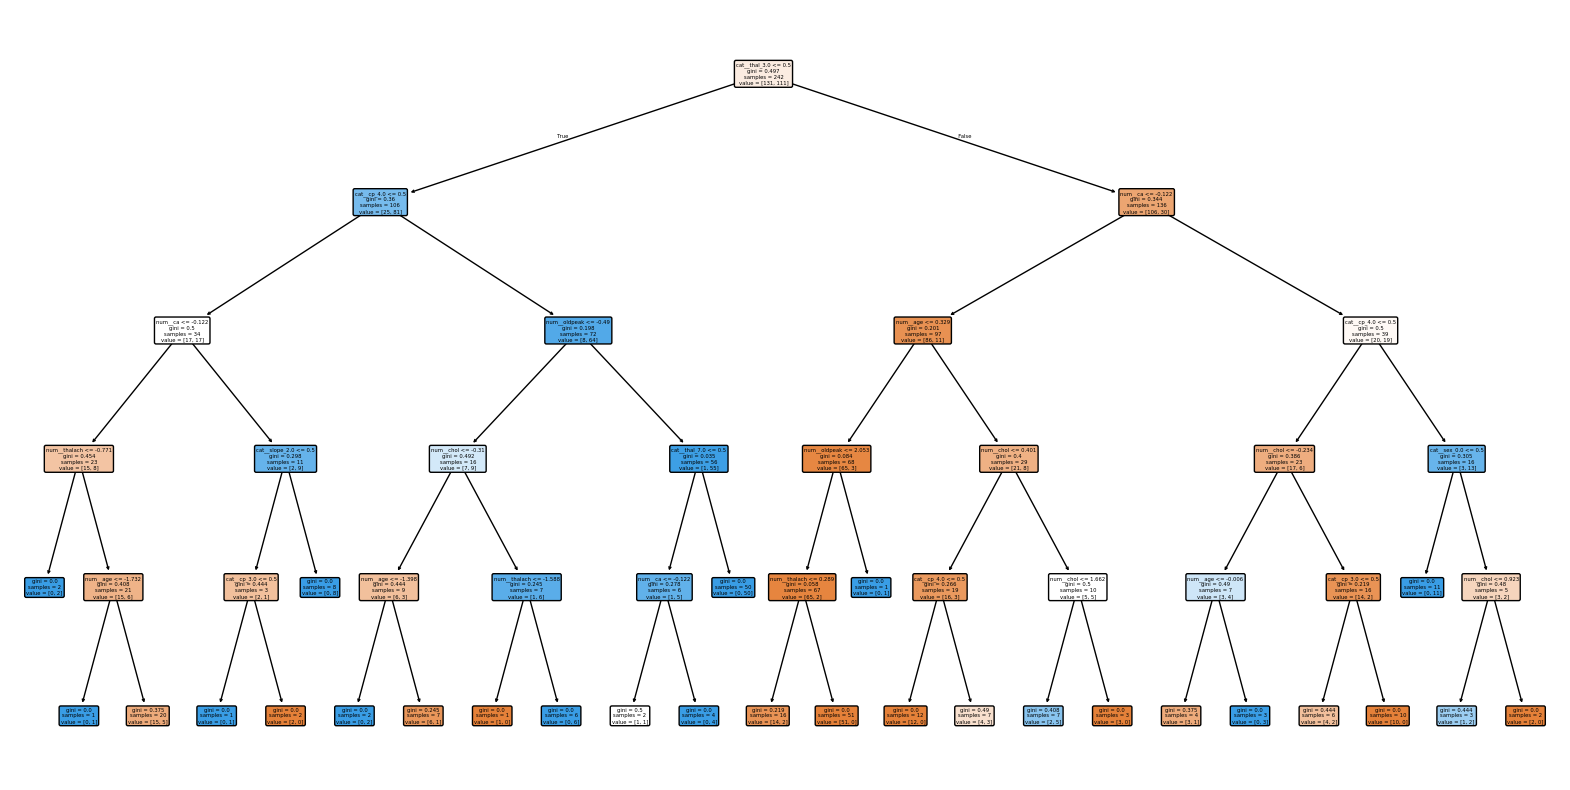

In [20]:
from sklearn.tree import plot_tree

tree = treePipe.named_steps['tree']
featureNames = treePipe.named_steps['preprocess'].get_feature_names_out()

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    tree,
    feature_names=featureNames,
    filled=True,
    rounded=True,
    ax=ax,
)
plt.show()

## Feature Importance

In [21]:
importances = pd.Series(tree.feature_importances_, index=featureNames)
importances[importances > 0].sort_values(ascending=False)

,0
cat__thal_3.0,0.371818
cat__cp_4.0,0.151595
num__ca,0.123916
num__chol,0.093424
num__age,0.078896
num__oldpeak,0.065886
num__thalach,0.041809
cat__sex_0.0,0.026142
cat__cp_3.0,0.022886
cat__slope_2.0,0.020485
